In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss

daten = pd.read_csv("data/bus48_modell.csv", parse_dates=["tag", "planzeit"])

# Ziel: 1 = mehr als 3 Min. zu spät, 0 = pünktlich
daten["zu_spaet"] = (daten["verspaetung_min"] > 3).astype(int)

print(f"Anteil > 3 Min. zu spät: {daten['zu_spaet'].mean():.1%}")

Anteil > 3 Min. zu spät: 10.3%


In [2]:
# Pro Tag, Richtung und Stunde: wie viele Busse waren zu spät, wie viele fuhren?
pro_tag = (
    daten.groupby(["richtung", "stunde", "tag"])["zu_spaet"]
    .agg(spaet="sum", fahrten="count")
    .reset_index()
    .sort_values("tag")
    .set_index("tag")
)

# Summe über die 7 Tage VOR jedem Tag (closed="left": der Tag selbst zählt nicht)
woche = (
    pro_tag.groupby(["richtung", "stunde"])[["spaet", "fahrten"]]
    .rolling("7D", closed="left")
    .sum()
    .reset_index()
)
woche["trend"] = woche["spaet"] / woche["fahrten"]

daten = daten.merge(woche[["richtung", "stunde", "tag", "trend"]],
                    on=["richtung", "stunde", "tag"], how="left")

print("Abfahrten ohne Trend (erste Tage):", daten["trend"].isna().sum())
daten[["tag", "stunde", "richtung", "trend"]].sample(5, random_state=1)

Abfahrten ohne Trend (erste Tage): 975


,tag,stunde,richtung,trend
150155,2026-08-26,11,stadtauswärts,0.040541
59963,2026-09-10,22,stadteinwärts,0.000000
180910,2026-08-31,7,stadteinwärts,0.091866
74208,2026-08-13,15,stadteinwärts,0.080119
100276,2026-09-17,18,stadteinwärts,0.176904


In [3]:
ZAHLEN = ["stunde", "wochentag", "wochenende", "schulferien", "temp", "regen_mm"]
KATEGORIEN = ["HALTESTELLEN_NAME", "richtung"]

def merkmale(spalten):
    return pd.get_dummies(daten[spalten + KATEGORIEN], columns=KATEGORIEN, dtype=int)

X_alt = merkmale(ZAHLEN)               # wie vorher
X = merkmale(ZAHLEN + ["trend"])       # neu mit Trend
y = daten["zu_spaet"]

GRENZE = pd.Timestamp("2026-10-26")
train = daten["tag"] < GRENZE
test = ~train
print("Training:", train.sum(), "· Test:", test.sum())

Training: 168360 · Test: 15181


In [4]:
# Baseline: Anteil verspäteter Busse pro Richtung und Stunde
quote = daten[train].groupby(["richtung", "stunde"])["zu_spaet"].mean()
schluessel = list(zip(daten.loc[test, "richtung"], daten.loc[test, "stunde"]))
baseline = pd.Series(schluessel, index=daten[test].index).map(quote).fillna(y[train].mean())

ergebnisse = {"Baseline": baseline}
for name, merkmal_tabelle in [("ohne Trend", X_alt), ("mit Trend", X)]:
    m = HistGradientBoostingClassifier(random_state=42)
    m.fit(merkmal_tabelle[train], y[train])
    ergebnisse[name] = m.predict_proba(merkmal_tabelle[test])[:, 1]

modell = m   # das letzte = mit Trend

for name, p in ergebnisse.items():
    print(f"{name:12s} AUC: {roc_auc_score(y[test], p):.3f}   "
          f"Brier: {brier_score_loss(y[test], p):.4f}")

Baseline     AUC: 0.789   Brier: 0.1207
ohne Trend   AUC: 0.806   Brier: 0.1087
mit Trend    AUC: 0.797   Brier: 0.1103


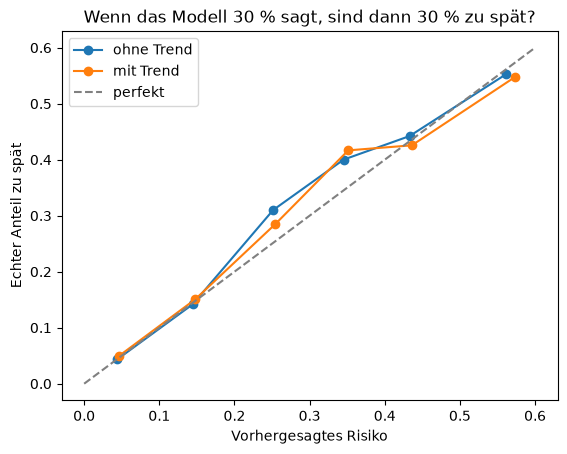

In [5]:
for name in ["ohne Trend", "mit Trend"]:
    v = pd.DataFrame({"risiko": ergebnisse[name], "echt": y[test].values})
    v["stufe"] = pd.cut(v["risiko"], bins=[0, .1, .2, .3, .4, .5, 1])
    t = v.groupby("stufe", observed=True).agg(vorhergesagt=("risiko", "mean"), echt=("echt", "mean"))
    plt.plot(t["vorhergesagt"], t["echt"], "o-", label=name)

plt.plot([0, 0.6], [0, 0.6], "--", color="grey", label="perfekt")
plt.xlabel("Vorhergesagtes Risiko")
plt.ylabel("Echter Anteil zu spät")
plt.title("Wenn das Modell 30 % sagt, sind dann 30 % zu spät?")
plt.legend()
plt.show()

In [6]:
def aktueller_trend(richtung, stunde):
    """Anteil zu spät in den letzten 7 Tagen der Daten, gleiche Richtung und Stunde."""
    ende = daten["tag"].max()
    teil = daten[(daten["richtung"] == richtung) & (daten["stunde"] == stunde)
                 & (daten["tag"] > ende - pd.Timedelta(days=7))]
    return teil["zu_spaet"].mean()

def risiko_vorhersagen(haltestelle, richtung, stunde, wochentag, regen_mm=0.0, temp=10.0, schulferien=False):
    zeile = pd.DataFrame([{
        "stunde": stunde, "wochentag": wochentag, "wochenende": wochentag >= 5,
        "schulferien": schulferien, "temp": temp, "regen_mm": regen_mm,
        "trend": aktueller_trend(richtung, stunde),
        "HALTESTELLEN_NAME": haltestelle, "richtung": richtung,
    }])
    zeile = pd.get_dummies(zeile, columns=KATEGORIEN, dtype=int).reindex(columns=X.columns, fill_value=0)
    return modell.predict_proba(zeile)[0, 1]

print(f"Trend 17 Uhr stadteinwärts, letzte 7 Tage: {aktueller_trend('stadteinwärts', 17):.0%}")
print(f"Di 07 Uhr, Ziegelei → Stadt, trocken: {risiko_vorhersagen('Ziegelei', 'stadteinwärts', 7, 1):.0%}")
print(f"Do 17 Uhr, Ziegelei → Stadt, Regen:   {risiko_vorhersagen('Ziegelei', 'stadteinwärts', 17, 3, regen_mm=3):.0%}")

Trend 17 Uhr stadteinwärts, letzte 7 Tage: 46%
Di 07 Uhr, Ziegelei → Stadt, trocken: 9%
Do 17 Uhr, Ziegelei → Stadt, Regen:   42%


In [ ]:
## Fazit
- Risiko-Modell (> 3 Min. zu spät) ohne Trend: AUC 0.806, Brier 0.109 – besser als Baseline (0.789 / 0.121)
- Trend-Merkmal (Anteil zu spät, letzte 7 Tage) verschlechtert leicht: AUC 0.797
- Grund: zu wenige Busse pro Stunde und Woche → Trend ist verrauscht
- **Entscheidung:** Modell ohne Trend für die App verwenden